# PRACTICA 2 AUTÓMATA CELULAR
# GARCÍA HERNÁNDEZ RODRIGO | 23070447


El estado del autómata se representa con una matríz booleana (es decir, contiene ceros y unos). Cada celda es o viva (uno) o muerta (cero). En cada paso, la supervivencia de cada celda (verde) se determina a partir de los valores de sus ocho vecinos (amarillos):

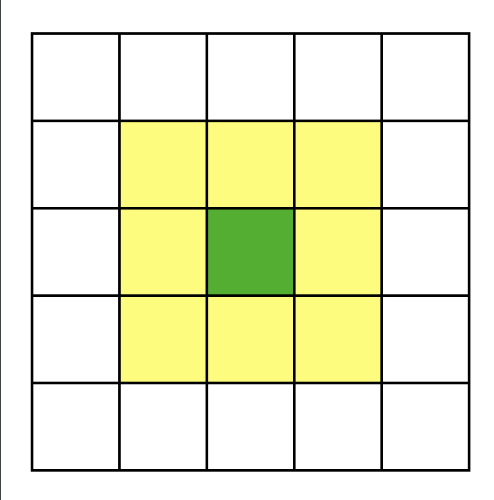

En los extremos de la matríz, las celdas simplemente tienen menos vecinos. (Otra alternativa sería considerar el espacio como un torus — pareciendo una dona — donde el extremo de abajo se reune con el extremo de arriba igual como los lados izquiero y derecho uno con otro.

La regla de supervivencia es sencilla: una celda está viva si exactamente tres vecinos suyos están vivos. Para comenzar, usamos números pseudoaleatorios como el estado inicial. 

# 1.- BAJAR EL CODIGO Y HACERLO FUNCIONAR

In [ ]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.25
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 100
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; 
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

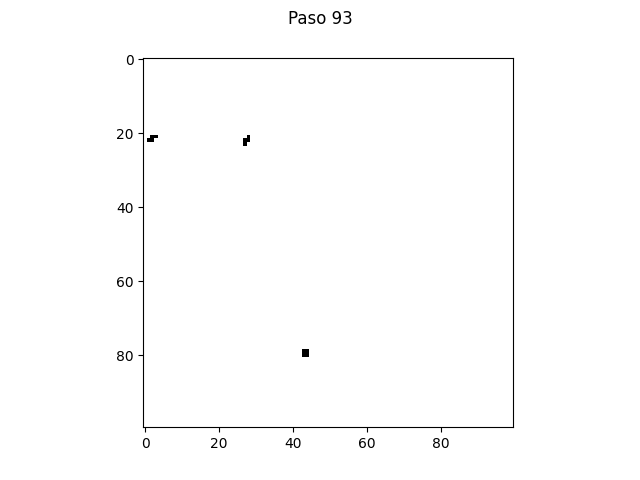

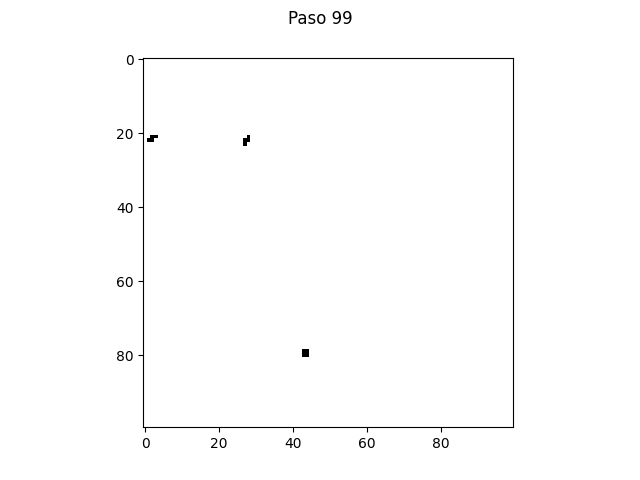

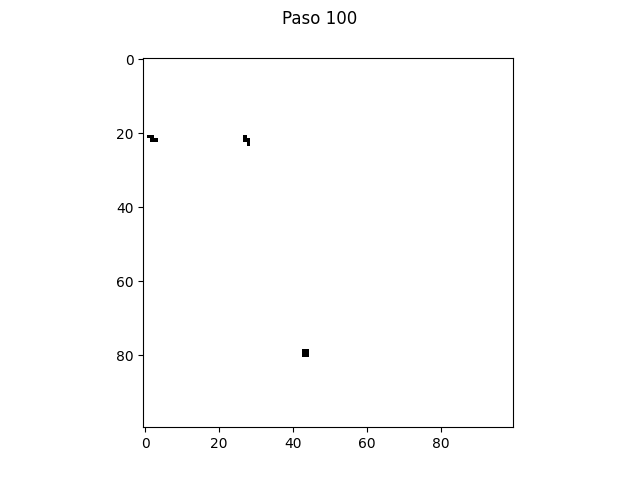

# 2.- REVISAR, ENTENDERLO E IDENTIFICAR EL OBJETIVO Y LOS PARAMETROS IMPORTANTES

In [4]:
Los parametros importantes son: 

DIM | TAMAÑO DEL TABLERO ( EN ESTE CASO 100) 100 X 100 CELULAS 
NUM | NÚMERO TOTAL DE CÉLULAS (DIM** 2)
P | PROBABILIDAD INICIAL QUE LA CELULA ESTE VIVA (0.25)
DUR | NÚMERO MAXIMO DE ITERACIONES (100)
LIM | DEFINIDO PERO NO SE UTILIZA (9) 
SEQ | CONTADOR PARA NOMBRAR A LAS IMAGENES (0) 
ACTUAL | ESTADO ACTUAL DEL TABLERO 


SyntaxError: invalid syntax (77116447.py, line 1)

valores = [1 * (random() < p) for i in range(num)]

genera las celulas iniciales con la probabilidad del 25% que cada celular nazca viva y el 75% que nazca muerta

1 representa celula viva
0 representa celular muerta

In [12]:
def paso(pos):
    fila = pos // dim
    columna = pos % dim

    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]

    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

print(paso)

<function paso at 0x78e77d4a53a0>


# Para cada celula, toma su vecindad de 3x3, es decir, la celula y las celulas de su alrededor 

Despues la funcion: 
np.sum(vecindad) - actual[fila, columna]

# cuenta unicamente las celulas vecinas vivas, excluyendo la celula central  

# Regla: 

La célula estará viva en la siguiente generación si tiene exactamente 3 vecinos vivos.
Esto significa que el comportamiento depende fuertemente de la densidad inicial p (probabilidad que nazca viva)

# Objetivo del programa 

El objetivo es estudiar como evoluciona una población de células a través del tiempo siguiendo una regla.
Cada célula solamente conoce el estado de sus vecinas. Sin embargo, al aplicar repetidamente la regla a todo el tablero aparecen comportamientos globales como desaparición de células, agrupaciones, patrones estables, oscilaciones, etc.
Una variable especialmente útil para estudiar esto es:

# vivos = sum(valores)

que indica cuántas células están vivas después de cada iteración.


# 3.- PROPONER CAMBIOS A LOS PARÁMETROS INICIALES EN FUNCIÓN DE ENTENDER EL IMPACTO DE LA RELACIÓN DE LOS PARÁMETROS Y EL OBJETIVO.


1.- CAMBIAR P PROBABILIDAD MANTENIENDO DIM Y DUR 

para entender que ocurre con la evolución cuando aumenta la proporción inical de celulas vivas

In [13]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.05
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 100
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 69
1 8
2 0


In [14]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.10
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 100
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 268
1 91
2 34
3 23
4 16
5 13
6 11
7 6
8 4
9 4
10 4
11 4
12 4
13 4
14 4
15 4
16 4
17 4
18 4
19 4
20 4
21 4
22 4
23 4
24 4
25 4
26 4
27 4
28 4
29 4
30 4
31 4
32 4
33 4
34 4
35 4
36 4
37 4
38 4
39 4
40 4
41 4
42 4
43 4
44 4
45 4
46 4
47 4
48 4
49 4
50 4
51 4
52 4
53 4
54 4
55 4
56 4
57 4
58 4
59 4
60 4
61 4
62 4
63 4
64 4
65 4
66 4
67 4
68 4
69 4
70 4
71 4
72 4
73 4
74 4
75 4
76 4
77 4
78 4
79 4
80 4
81 4
82 4
83 4
84 4
85 4
86 4
87 4
88 4
89 4
90 4
91 4
92 4
93 4
94 4
95 4
96 4
97 4
98 4
99 4


In [15]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.50
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 100
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 2178
1 1553
2 1094
3 688
4 403
5 218
6 123
7 64
8 41
9 29
10 27
11 26
12 22
13 20
14 20
15 20
16 20
17 20
18 20
19 20
20 20
21 20
22 20
23 20
24 20
25 20
26 20
27 20
28 20
29 20
30 20
31 20
32 20
33 20
34 20
35 20
36 20
37 20
38 20
39 20
40 20
41 20
42 20
43 20
44 20
45 20
46 20
47 20
48 20
49 20
50 20
51 20
52 20
53 20
54 20
55 20
56 20
57 20
58 20
59 20
60 20
61 20
62 20
63 20
64 20
65 20
66 20
67 20
68 20
69 20
70 20
71 20
72 20
73 20
74 20
75 20
76 20
77 20
78 20
79 20
80 20
81 20
82 20
83 20
84 20
85 20
86 20
87 20
88 20
89 20
90 20
91 20
92 20
93 20
94 20
95 20
96 20
97 20
98 20
99 20


In [17]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.75
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 100
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 331
1 96
2 32
3 11
4 4
5 1
6 0


2. CAMBIAR DIM

Modificar el tamaño del sistema para ver si el tamaño modifica del tablero modifica el comportamiento general del sistema

In [18]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 50
num = dim**2
p = 0.25
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 100
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 446
1 315
2 206
3 142
4 95
5 63
6 44
7 25
8 17
9 10
10 8
11 8
12 8
13 8
14 8
15 8
16 8
17 8
18 8
19 8
20 8
21 8
22 8
23 8
24 8
25 8
26 8
27 8
28 8
29 8
30 8
31 8
32 8
33 8
34 8
35 8
36 8
37 8
38 8
39 8
40 8
41 8
42 8
43 8
44 8
45 8
46 8
47 8
48 8
49 8
50 8
51 8
52 8
53 8
54 8
55 8
56 8
57 8
58 8
59 8
60 8
61 8
62 8
63 8
64 8
65 8
66 8
67 8
68 8
69 8
70 8
71 8
72 8
73 8
74 8
75 8
76 8
77 8
78 8
79 8
80 8
81 8
82 8
83 8
84 8
85 8
86 8
87 8
88 8
89 8
90 8
91 8
92 8
93 8
94 8
95 8
96 8
97 8
98 8
99 8


In [19]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 200
num = dim**2
p = 0.25
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 100
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 8200
1 6030
2 4144
3 2728
4 1574
5 839
6 410
7 203
8 104
9 70
10 53
11 50
12 49
13 48
14 46
15 46
16 46
17 46
18 46
19 46
20 46
21 46
22 46
23 46
24 46
25 46
26 46
27 46
28 46
29 46
30 46
31 46
32 46
33 46
34 46
35 46
36 46
37 46
38 46
39 46
40 46
41 46
42 46
43 46
44 46
45 46
46 46
47 46
48 46
49 46
50 46
51 46
52 46
53 46
54 46
55 46
56 46
57 46
58 46
59 46
60 46
61 46
62 46
63 46
64 46
65 46
66 46
67 46
68 46
69 46
70 46
71 46
72 46
73 46
74 46
75 46
76 46
77 46
78 46
79 46
80 46
81 46
82 46
83 46
84 46
85 46
86 46
87 46
88 46
89 46
90 46
91 46
92 46
93 46
94 46
95 46
96 46
97 46
98 46
99 46


In [21]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.25
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 100
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 2001
1 1509
2 1065
3 691
4 426
5 228
6 118
7 73
8 48
9 37
10 30
11 28
12 28
13 28
14 28
15 28
16 28
17 28
18 28
19 28
20 28
21 28
22 28
23 28
24 28
25 28
26 28
27 28
28 28
29 28
30 28
31 28
32 28
33 28
34 28
35 28
36 28
37 28
38 28
39 28
40 28
41 28
42 28
43 28
44 28
45 28
46 28
47 28
48 28
49 28
50 28
51 28
52 28
53 28
54 28
55 28
56 28
57 28
58 28
59 28
60 28
61 28
62 28
63 28
64 28
65 28
66 28
67 28
68 28
69 28
70 28
71 28
72 28
73 28
74 28
75 28
76 28
77 28
78 28
79 28
80 28
81 28
82 28
83 28
84 28
85 28
86 28
87 28
88 28
89 28
90 28
91 28
92 28
93 28
94 28
95 28
96 28
97 28
98 28
99 28


3.- CAMBIAR DUR 
modifica el tiempo durante el cual observamos la evolución 

In [22]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.25
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 50
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 1973
1 1403
2 914
3 553
4 341
5 171
6 84
7 47
8 27
9 24
10 24
11 24
12 24
13 24
14 24
15 24
16 24
17 24
18 24
19 24
20 24
21 24
22 24
23 24
24 24
25 24
26 24
27 24
28 24
29 24
30 24
31 24
32 24
33 24
34 24
35 24
36 24
37 24
38 24
39 24
40 24
41 24
42 24
43 24
44 24
45 24
46 24
47 24
48 24
49 24


In [23]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.25
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 200
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 1964
1 1420
2 979
3 596
4 334
5 189
6 108
7 58
8 39
9 29
10 22
11 16
12 14
13 12
14 12
15 12
16 12
17 12
18 12
19 12
20 12
21 12
22 12
23 12
24 12
25 12
26 12
27 12
28 12
29 12
30 12
31 12
32 12
33 12
34 12
35 12
36 12
37 12
38 12
39 12
40 12
41 12
42 12
43 12
44 12
45 12
46 12
47 12
48 12
49 12
50 12
51 12
52 12
53 12
54 12
55 12
56 12
57 12
58 12
59 12
60 12
61 12
62 12
63 12
64 12
65 12
66 12
67 12
68 12
69 12
70 12
71 12
72 12
73 12
74 12
75 12
76 12
77 12
78 12
79 12
80 12
81 12
82 12
83 12
84 12
85 12
86 12
87 12
88 12
89 12
90 12
91 12
92 12
93 12
94 12
95 12
96 12
97 12
98 12
99 12
100 12
101 12
102 12
103 12
104 12
105 12
106 12
107 12
108 12
109 12
110 12
111 12
112 12
113 12
114 12
115 12
116 12
117 12
118 12
119 12
120 12
121 12
122 12
123 12
124 12
125 12
126 12
127 12
128 12
129 12
130 12
131 12
132 12
133 12
134 12
135 12
136 12
137 12
138 12
139 12
140 12
141 12
142 12
143 12
144 12
145 12
146 12
147 12
148 12
149 12
150 12
151 12
152 12
153 12
154 12
155 12
156 12
15

In [24]:
import numpy as np 
from random import random
import matplotlib.cm as cm
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.25
valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x]  for x in range(num)])

def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

dur = 10
lim = 9
seq = 0

if __name__ == "__main__":
    fig = plt.figure()
    plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
    fig.suptitle('Estado inicial')
    plt.savefig('p2_t0_p.png')
    plt.close()
    for iteracion in range(dur):
        valores = [paso(x) for x in range(num)]
        vivos = sum(valores)
        print(iteracion, vivos)
        if vivos == 0:
            break; # nadie vivo
        actual = np.reshape(valores, (dim, dim))
        if dur - iteracion < 9:  
            fig = plt.figure()
            plt.imshow(actual, interpolation='nearest', cmap=cm.Greys)
            fig.suptitle('Paso {:d}'.format(iteracion + 1))
            plt.savefig('p2_t{:d}_p.png'.format(seq))
            seq += 1
            plt.close()

0 2087
1 1615
2 1104
3 743
4 462
5 260
6 152
7 78
8 37
9 20


# OBJETIVO DEL PROGRAMA
El objetivo es estudiar cómo evoluciona una población de células a través del tiempo siguiendo una regla.
Cada célula solamente conoce el estado de sus vecinos, sin embargo, al aplicar repetidamente la regla a todo el tablero aparecen comportamientos globales: desaparición de células, agrupaciones, patrones estables, oscilaciones, etc.
Una variable especialmente útil para estudiar esto es

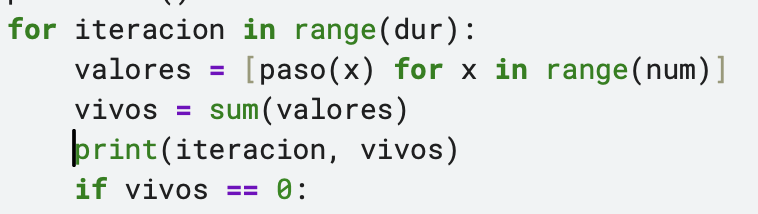

que indica cuántas células están vivas después de cada iteración.

# GRAFICA | VISUALIZAR ESTADO DE LAS CELULAS CON EL PASO DE LAS ITERACIONES

el programa imprime (iteracion, vivos) pero después no guarda estos datos, voy a modificarlo  para guardar el numero de celulas vivas y posteriormente graficarlo. 

0 305
1 103
2 38
3 15
4 10
5 8
6 8
7 8
8 8
9 8
10 8
11 8
12 8
13 8
14 8
15 8
16 8
17 8
18 8
19 8
20 8
21 8
22 8
23 8
24 8
25 8
26 8
27 8
28 8
29 8
30 8
31 8
32 8
33 8
34 8
35 8
36 8
37 8
38 8
39 8
40 8
41 8
42 8
43 8
44 8
45 8
46 8
47 8
48 8
49 8
50 8
51 8
52 8
53 8
54 8
55 8
56 8
57 8
58 8
59 8
60 8
61 8
62 8
63 8
64 8
65 8
66 8
67 8
68 8
69 8
70 8
71 8
72 8
73 8
74 8
75 8
76 8
77 8
78 8
79 8
80 8
81 8
82 8
83 8
84 8
85 8
86 8
87 8
88 8
89 8
90 8
91 8
92 8
93 8
94 8
95 8
96 8
97 8
98 8
99 8


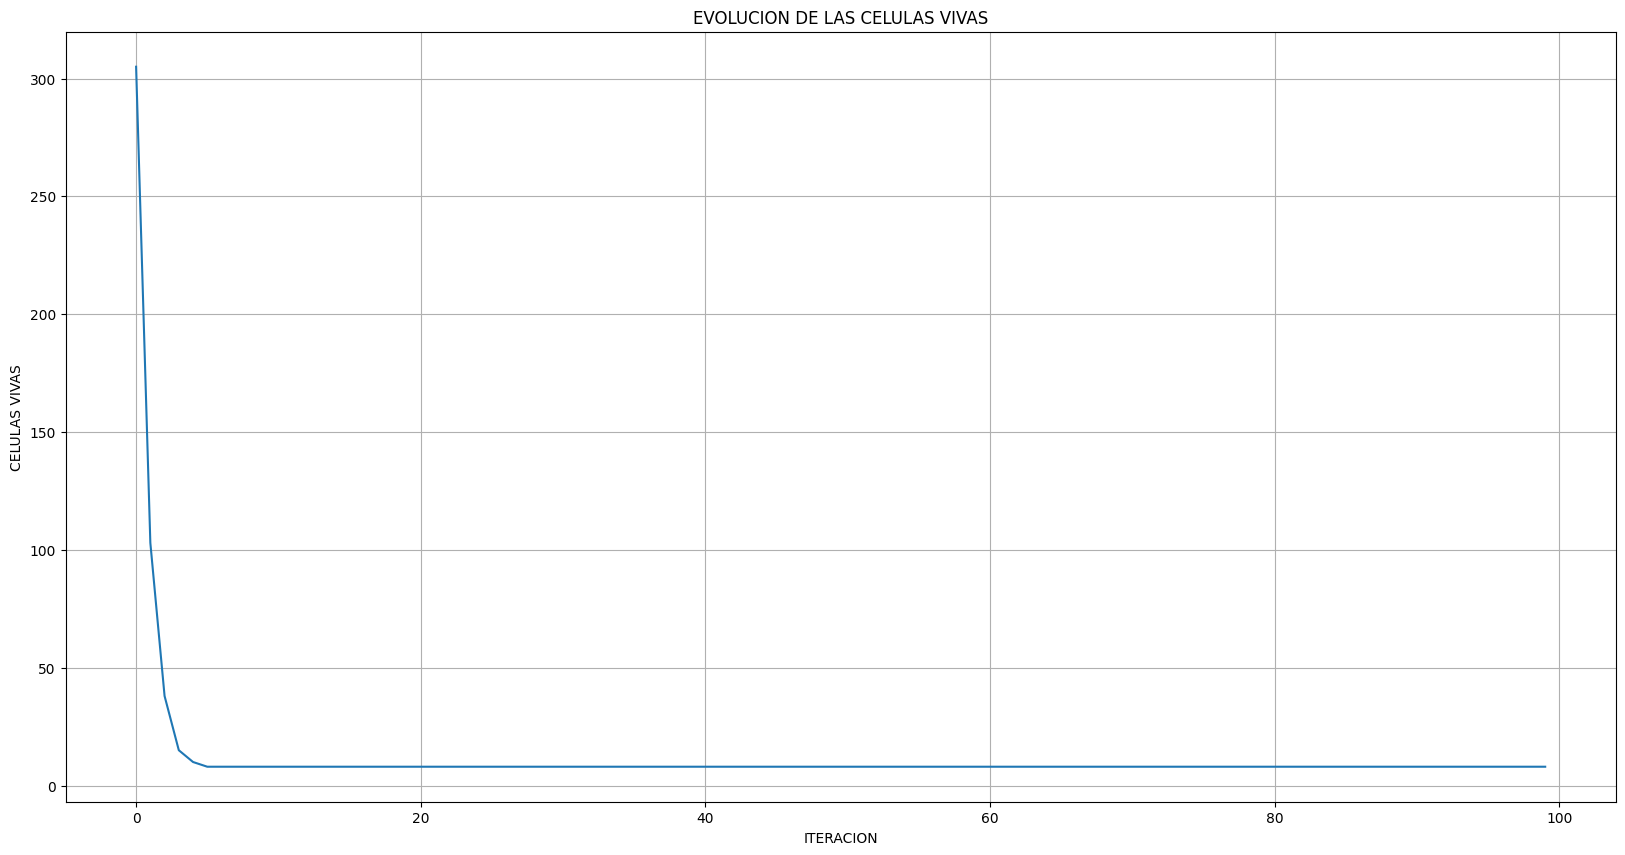

In [25]:
import numpy as np
from random import random
import matplotlib.pyplot as plt

dim = 100
num = dim**2
p = 0.10

valores = [1 * (random() < p) for i in range(num)]
actual = np.reshape(valores, (dim, dim))

def mapeo(pos):
    fila = pos // dim
    columna = pos % dim
    return actual[fila, columna]

assert all([mapeo(x) == valores[x] for x in range(num)])


def paso(pos):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[
        max(0, fila - 1):min(dim, fila + 2),
        max(0, columna - 1):min(dim, columna + 2)
    ]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)


dur = 100

historial_vivos = []
for iteracion in range(dur):
    valores = [paso(x) for x in range(num)]
    vivos = sum(valores)
    historial_vivos.append(vivos)
    print(iteracion, vivos)

    if vivos == 0:
        break
    actual = np.reshape(valores, (dim, dim))

plt.figure(figsize=(20, 10))
plt.plot(historial_vivos)
plt.xlabel("ITERACION")
plt.ylabel("CELULAS VIVAS")
plt.title("EVOLUCION DE LAS CELULAS VIVAS")
plt.grid(True)
plt.show()

# GRAFICA | COMPARAR DIFERENTES VALORES DE P EN UNA MISMA GRAFICA

COmparacion directa con p = 0.05, 0.10, 0.25, 0.50, 0.75

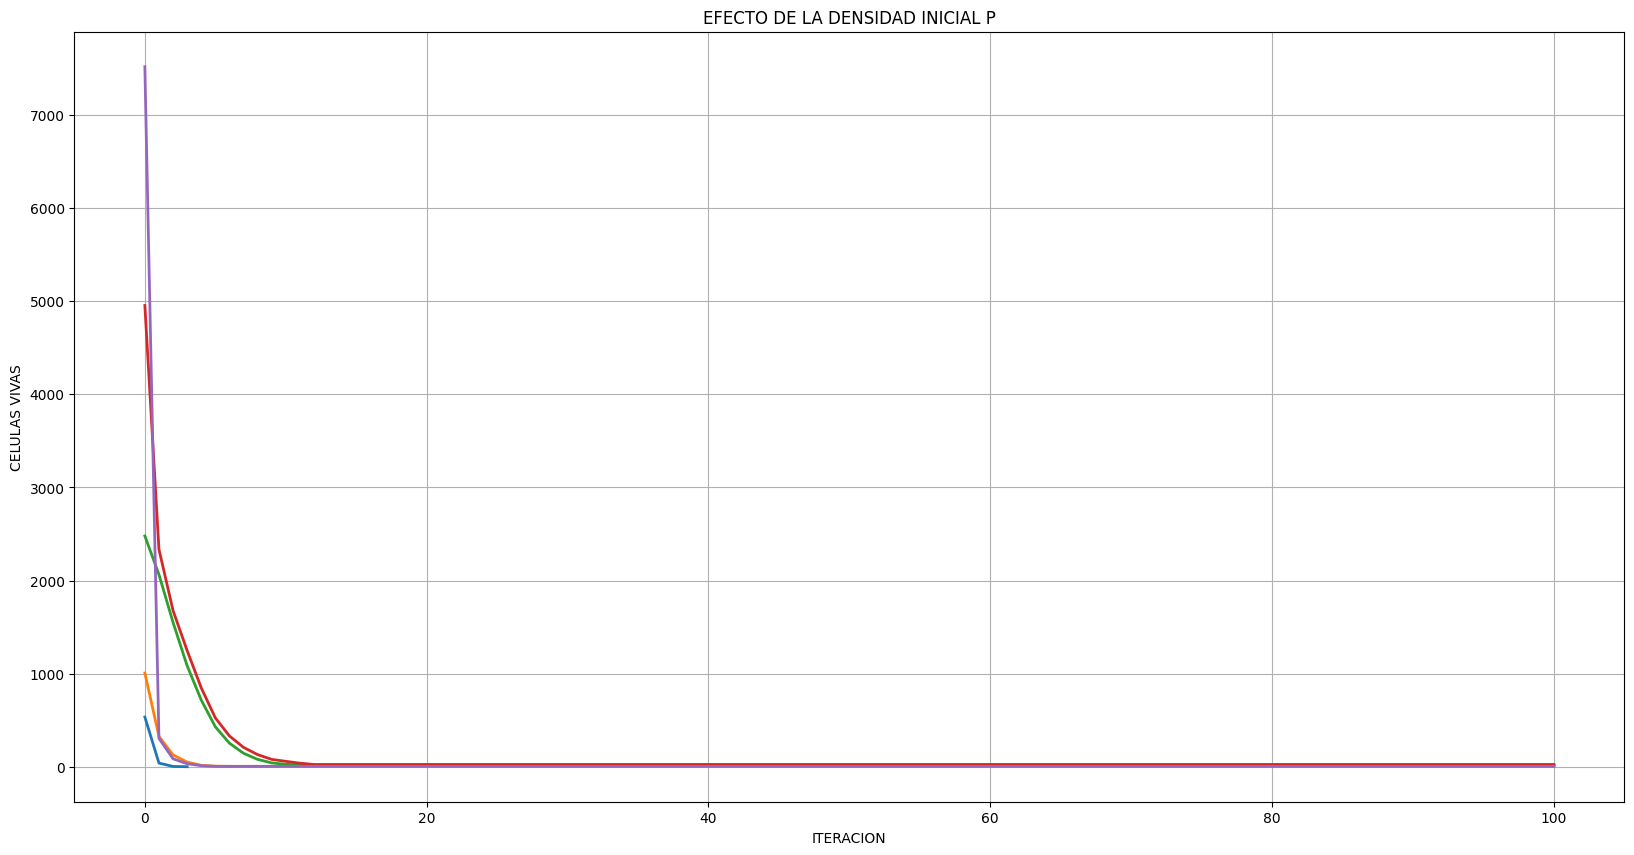

In [22]:
plt.figure(figsize=(20, 10))

p_values = [0.05, 0.10, 0.25, 0.50, 0.75]

for p in p_values:
    valores = [1 * (random() < p) for i in range(num)]
    actual = np.reshape(valores, (dim, dim))
    
    vivos = sum(valores)
    historial_vivos = [vivos]

    for iteracion in range(dur):
        valores = [paso(x, actual) for x in range(num)]
        vivos = sum(valores)
        historial_vivos.append(vivos)
        actual = np.reshape(valores, (dim, dim))
        
        if vivos == 0:
            break

    plt.plot(historial_vivos, label=f"p = {p}", linewidth=2)

plt.xlabel("ITERACION")
plt.ylabel("CELULAS VIVAS")
plt.title("EFECTO DE LA DENSIDAD INICIAL P")
plt.legend
plt.grid(True)
plt.show()

p (Inicial)  | Vivas        | Vivas FINAL  | Iteraciones 
0.05         | 547          | 0            | 4           
0.10         | 966          | 8            | 100         
0.25         | 2462         | 46           | 100         
0.50         | 5038         | 12           | 100         
0.75         | 7439         | 0            | 5           


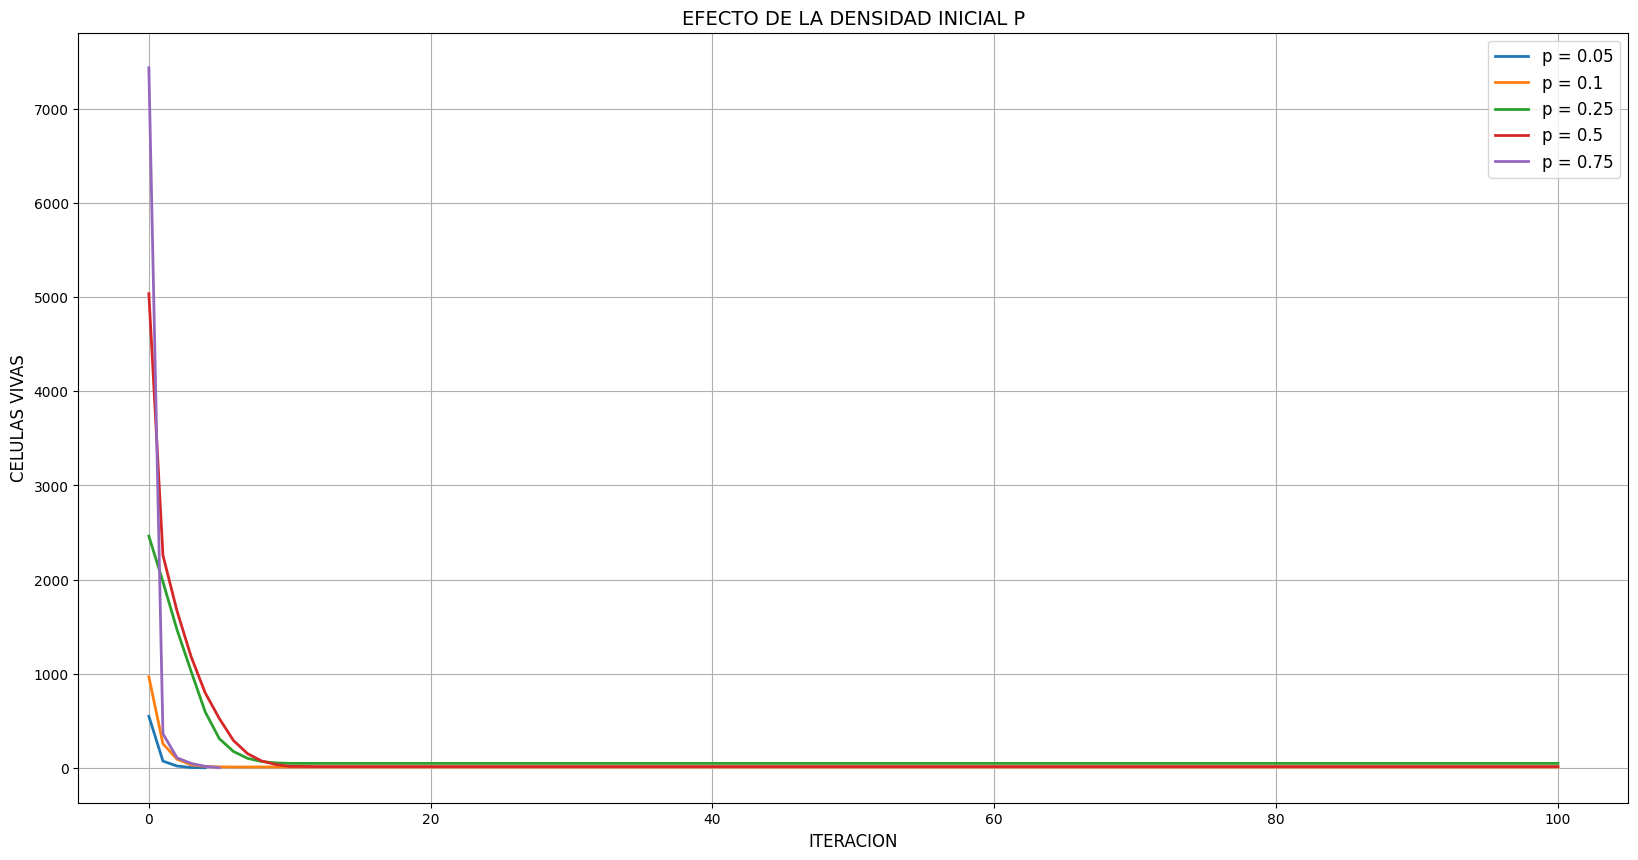

In [32]:
import numpy as np
from random import random
import matplotlib.pyplot as plt

dim = 100
num = dim**2
dur = 100

def paso(pos, actual):
    fila = pos // dim
    columna = pos % dim
    vecindad = actual[max(0, fila - 1):min(dim, fila + 2),
                      max(0, columna - 1):min(dim, columna + 2)]
    return 1 * (np.sum(vecindad) - actual[fila, columna] == 3)

p_values = [0.05, 0.10, 0.25, 0.50, 0.75]
plt.figure(figsize=(20, 10))


print(f"{"p (Inicial)":<12} | {"Vivas":<12} | {"Vivas FINAL":<12} | {"Iteraciones":<12}")


for p in p_values:
    valores = [1 * (random() < p) for i in range(num)]
    actual = np.reshape(valores, (dim, dim))
    
    vivos = sum(valores)
    historial_vivos = [vivos]

    for iteracion in range(dur):
        valores = [paso(x, actual) for x in range(num)]
        vivos = sum(valores)
        historial_vivos.append(vivos)
        actual = np.reshape(valores, (dim, dim))
        
        if vivos == 0:
            break
            
    vivas_inicial = historial_vivos[0]
    vivas_final = historial_vivos[-1]
    total_iteraciones = len(historial_vivos) - 1
    print(f"{p:<12.2f} | {vivas_inicial:<12d} | {vivas_final:<12d} | {total_iteraciones:<12d}")

    plt.plot(historial_vivos, label=f"p = {p}", linewidth=2)


plt.xlabel("ITERACION", fontsize=12)
plt.ylabel("CELULAS VIVAS", fontsize=12)
plt.title("EFECTO DE LA DENSIDAD INICIAL P", fontsize=14)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()

# PARAMETROS IMPORTANTES | CONCLUSIONES

p es la densidad inicial 
p bajo - pocas celulas inicialmente
p alto - muchas celulas inicialmente
La regla exige 3exactamente 3 vecinos por lo que cambiar la densidad inicial puede cambiar mucho la evolucion 



DIM es el tamaño del sistema 
Nos permite observar el comportamiento si tenemos un tablero pequeño o grande 



REGLA == 3 
tenemos en el codigo
np.sum(vecindad) - actual[fila, columna] == 3
Se debe cumplir la condición de los 3 vecinos. 

# CONCLUSION

El análisis del autómata celular permitió entender que los parámetros iniciales afectan la evolución. Al modificar principalmente p, dim y dur, se observaron cambios en la cantidad de células vivas y en los patrones generados. Las gráficas facilitaron la comparación de estos cambios y mostraron que la densidad inicial (p) tiene un efecto importante sobre el comportamiento del sistema. En conclusión, pequeñas modificaciones en los parámetros pueden producir diferentes resultados, demostrando la importancia de analizar la relación entre las condiciones iniciales y las reglas del autómata.
Pequeñas variaciones en el parámetro de entrada p cambian la esperanza de vida del sistema, pasando de una extinción  (p=0.05 y p=0.75) a una estable como (p=0.25). Esto demuestra que este autómata celular es un sistema altamente sensible a sus condiciones iniciales donde la densidad para la persistencia se encuentra cerca de p 0.25

dim: Determina el techo de capacidad alcanzando hasta 7,439 células vivas para P =0.75, Sin embargo, sin importar cuán grande sea el plano, las reglas de vecindad comprimen la densidad inicial hacia mínimos locales estables o la extinción como lo fue en solo 5 iteraciones

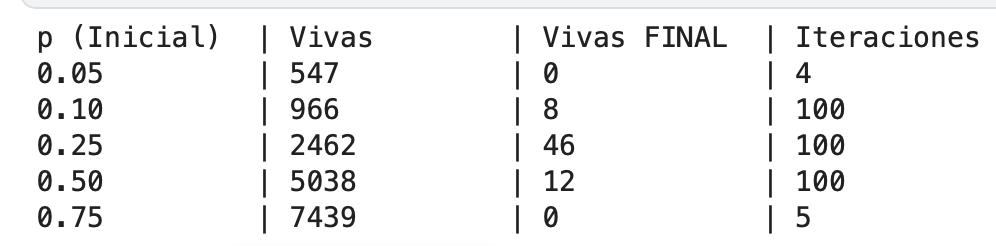

dur: Fijar la duración a dur=100 iteraciones permite confirmar que la caída poblacional ocurre durante las primeras 15 a 20 iteraciones. A partir de este umbral, la población deja de decrecer  y entra en un estado estacionario, tal como se evidencia en el registro donde la población se mantiene estrictamente constante en 8 células vivas desde la iteracion 8 hasta la 99

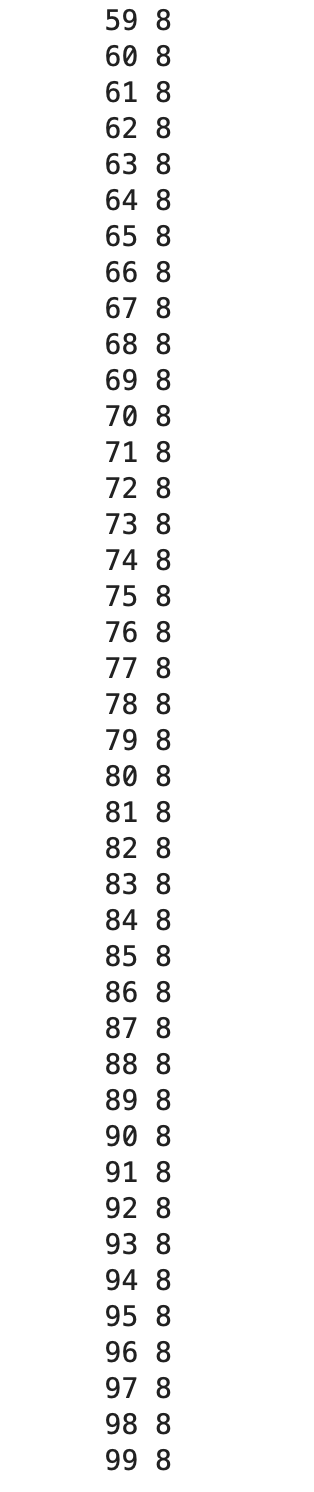

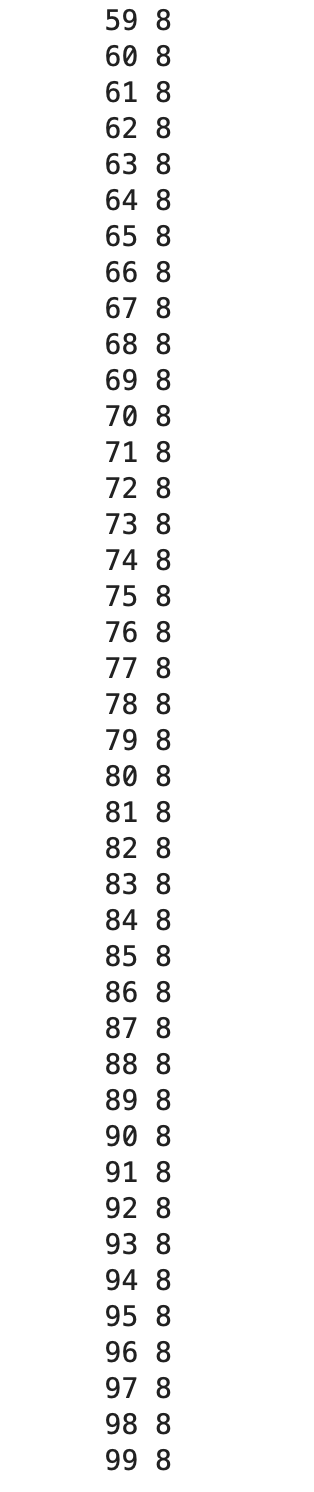